In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625





Analysing 55 (beta,time) snapshots across 55 workers ...
IMF 1
IMF 1
IMF 2
IMF 2
IMF 3
IMF 3
IMF 4
IMF 4
IMF 1
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 4
input mask not integer, making it so
beta=16, t=225: 79 sheets
beta=16, t=245: 99 sheets
beta=16, t=240: 100 sheets
beta=16, t=235: 102 sheets
beta=16, t=205: 105 sheets
beta=16, t=210: 106 sheets
beta=16, t=230: 108 sheets
beta=16, t=220: 109 

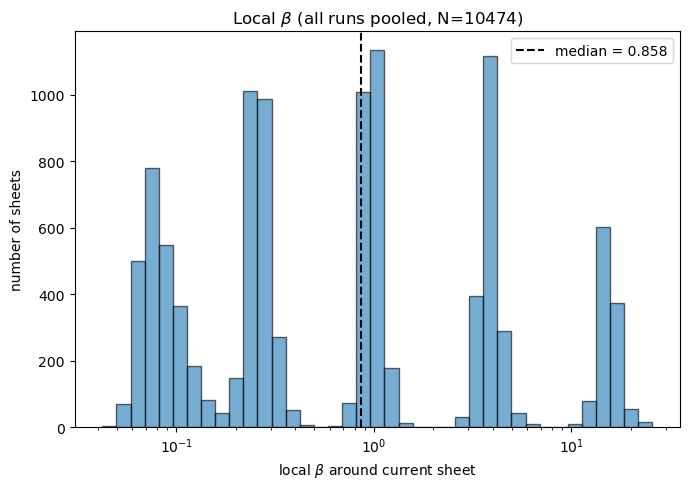

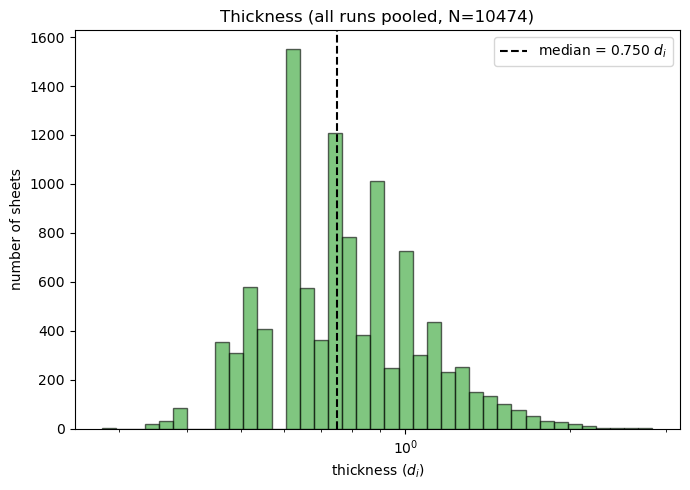

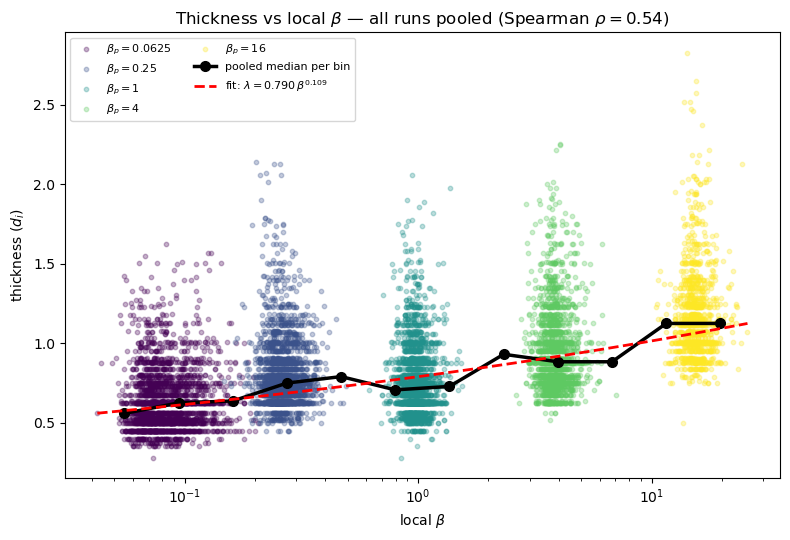


--- pooled sample ---
total sheets           : 10474
local beta  : median = 0.858  (range 0.0422-25.8)
thickness   : median = 0.750 d_i
power-law fit          : lambda = 0.790 * beta_local^0.109
Spearman rho (thick,lb): 0.541  (p=0)

--- per-run median local beta vs nominal (calibration glance) ---
  beta_p       N  median local beta
  0.0625    2569              0.080
    0.25    2482              0.260
       1    2409              0.970
       4    1882              3.833
      16    1132             15.353

Everything saved in:  cs_beta_pooled_ALL_t200-250/


In [7]:
# ============================================================
#  Current sheets: thickness vs LOCAL ELECTRON beta  --  beta_e scan
#  proton beta fixed at 1, electron beta varied; ALL runs pooled
#  ------------------------------------------------------------
#  Electron beta is set by the isothermal closure, not measured from particles:
#     P_e = n * T_e0,   T_e0 = beta_e / 2   (from the initial conditions)
#     beta_e(x) = 2 P_e / |B|^2 = 2 n T_e0 / |B|^2
#  Because beta_p is fixed, local proton beta hardly varies run-to-run, but local
#  ELECTRON beta scales with the run -> it is the informative x-axis here.
#
#  Per sheet we record local electron beta (primary) AND local proton beta
#  (reference), both as the median over a rectangle around the sheet.
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.stats import spearmanr
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
BETA_P    = 1                              # proton beta -- FIXED
BETAS_E   = [0.0625, 0.25, 1, 4, 16]       # electron-beta runs to pool together
TIMES     = list(range(200, 251, 5))
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_betae_scan_pooled_bp{BETA_P}_t{TIMES[0]}-{TIMES[-1]}")

px_per_di = 16.0
box_pad   = 5
dx = dy   = 0.0625

P_PAR_TAG = "Ppar1"                        # proton parallel  pressure tag
P_PER_TAG = "Pper1"                        # proton perpendicular pressure tag
N_TAG     = "n"                            # density tag  (n_ApJ_t{t}.h5)

THREADS_PER_WORKER = 1
N_BINS_MED = 12
MIN_PER_BIN = 10

# beta_p=1 detection parameters, held FIXED across the beta_e scan
FILTER_PARAMS_BETA_E = {
    0.0625: (3, 2.5), 0.25: (3, 2.5), 1: (3, 2.5), 4: (3, 2.5), 16: (3, 2.5),
}

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(beta_e):
    return FILTER_PARAMS_BETA_E[beta_e]


def base_path(beta_e):
    return f"{base_root}/beta_p_{BETA_P}/beta_e_{beta_e}/"


def load(tag, beta_e, time):
    with h5py.File(f"{base_path(beta_e)}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


def _init_worker(n_threads):
    try:
        from threadpoolctl import threadpool_limits
        threadpool_limits(n_threads)
    except Exception:
        pass


# ============================================================
# One (beta_e, time) snapshot
#   -> (beta_e, time, thickness_di[], local_beta_p[], local_beta_e[])
# ============================================================
def analyze_snapshot(beta_e, time):
    Bx, By, Bz = load("Bx", beta_e, time), load("By", beta_e, time), load("Bz", beta_e, time)
    B2 = Bx**2 + By**2 + Bz**2

    # proton beta field (kinetic pressure moments)
    P_par  = load(P_PAR_TAG, beta_e, time)
    P_perp = load(P_PER_TAG, beta_e, time)
    P_scalar = (P_par + 2.0 * P_perp) / 3.0
    beta_p_field = 2.0 * P_scalar / B2

    # electron beta field (isothermal closure): P_e = n * T_e0, T_e0 = beta_e / 2
    n = load(N_TAG, beta_e, time)
    T_e0 = beta_e / 2.0
    P_e = n * T_e0
    beta_e_field = 2.0 * P_e / B2

    # --- detect sheets (filtered B, cached; keyed by beta_p AND beta_e) ---
    n_iter, Xi = filter_params(beta_e)
    cache_file = f"{cache_dir}/filtered_bp{BETA_P}_be{beta_e}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=2)
    n_sheets = labeled.max()
    all_sheets_mask = labeled > 0

    thick, lbeta_p, lbeta_e = [], [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)

        dist = ndi.distance_transform_edt(region)
        thick_di = (2 * dist.max()) / px_per_di

        xs_r, ys_r = np.where(region)
        bx0 = max(0, xs_r.min() - box_pad)
        bx1 = min(B2.shape[0], xs_r.max() + box_pad + 1)
        by0 = max(0, ys_r.min() - box_pad)
        by1 = min(B2.shape[1], ys_r.max() + box_pad + 1)
        box_region = np.zeros_like(region)
        box_region[bx0:bx1, by0:by1] = True
        box_region = box_region & ~all_sheets_mask
        if box_region.sum() < 20:
            continue

        thick.append(thick_di)
        lbeta_p.append(float(np.median(beta_p_field[box_region])))
        lbeta_e.append(float(np.median(beta_e_field[box_region])))

    return beta_e, time, np.array(thick), np.array(lbeta_p), np.array(lbeta_e)


# ============================================================
# STEP 1. Run every (beta_e, time) in parallel, pool EVERYTHING
# ============================================================
tasks = [(be, t) for be in BETAS_E for t in TIMES]
n_workers = min(len(tasks), os.cpu_count() or 1)

run_beta_e, snap_time, thickness, local_beta_p, local_beta_e = [], [], [], [], []

def _store(res):
    be, t, th, lbp, lbe = res
    run_beta_e.extend([be] * len(th))
    snap_time.extend([t] * len(th))
    thickness.extend(th)
    local_beta_p.extend(lbp)
    local_beta_e.extend(lbe)
    print(f"beta_e={be}, t={t}: {len(th)} sheets", flush=True)

if n_workers == 1:
    for be, t in tasks:
        try:
            _store(analyze_snapshot(be, t))
        except FileNotFoundError:
            print(f"beta_e={be}, t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Analysing {len(tasks)} (beta_e,time) snapshots across {n_workers} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(analyze_snapshot, be, t): (be, t) for be, t in tasks}
        for fut in as_completed(futs):
            be, t = futs[fut]
            try:
                _store(fut.result())
            except FileNotFoundError:
                print(f"beta_e={be}, t={t}: missing file, skipped", flush=True)

run_beta_e   = np.array(run_beta_e)
snap_time    = np.array(snap_time)
thickness    = np.array(thickness)
local_beta_p = np.array(local_beta_p)
local_beta_e = np.array(local_beta_e)
print(f"\npooled {len(thickness)} sheets total (all beta_e runs, all snapshots)", flush=True)
if len(thickness) == 0:
    raise SystemExit("No sheets pooled (check paths/times).")

np.savez_compressed(f"{out_dir}/pooled_all.npz",
                    beta_e=run_beta_e, time=snap_time, thickness_di=thickness,
                    local_beta_p=local_beta_p, local_beta_e=local_beta_e)
with open(f"{out_dir}/pooled_all.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_e", "time", "thickness_di", "local_beta_e", "local_beta_p"])
    for i in range(len(thickness)):
        w.writerow([run_beta_e[i], int(snap_time[i]), thickness[i],
                    local_beta_e[i], local_beta_p[i]])


# ============================================================
# STEP 2. Pooled distributions (local electron beta + thickness)
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta_e,
         bins=np.logspace(np.log10(local_beta_e.min()), np.log10(local_beta_e.max()), 40),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta_e), color="black", linestyle="--",
            label=f"median = {np.median(local_beta_e):.3f}")
plt.xscale("log")
plt.xlabel(r"local electron $\beta_e$ around current sheet"); plt.ylabel("number of sheets")
plt.title(rf"Local $\beta_e$ ($\beta_p={BETA_P}$, $\beta_e$ scan pooled, N={len(local_beta_e)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_betae_pooled.png", dpi=300); plt.show()

plt.figure(figsize=(7, 5))
plt.hist(thickness,
         bins=np.logspace(np.log10(thickness.min()), np.log10(thickness.max()), 40),
         alpha=0.6, edgecolor="black", color="tab:green")
plt.axvline(np.median(thickness), color="black", linestyle="--",
            label=f"median = {np.median(thickness):.3f} $d_i$")
plt.xscale("log")
plt.xlabel(r"thickness $(d_i)$"); plt.ylabel("number of sheets")
plt.title(rf"Thickness ($\beta_p={BETA_P}$, $\beta_e$ scan pooled, N={len(thickness)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_thickness_pooled.png", dpi=300); plt.show()


# ============================================================
# STEP 3. Thickness vs local ELECTRON beta (pooled) + power-law fit
# ============================================================
edges = np.logspace(np.log10(local_beta_e.min()), np.log10(local_beta_e.max()), N_BINS_MED + 1)
cen, med, cnt = [], [], []
summary_rows = []
for i in range(N_BINS_MED):
    lo, hi = edges[i], edges[i + 1]
    sel = (local_beta_e >= lo) & (local_beta_e < hi)
    if sel.sum() == 0:
        continue
    cen.append(np.sqrt(lo * hi)); med.append(np.median(thickness[sel])); cnt.append(int(sel.sum()))
    summary_rows.append([lo, hi, int(sel.sum()),
                         np.median(thickness[sel]), np.mean(thickness[sel])])
cen, med, cnt = np.array(cen), np.array(med), np.array(cnt)

with open(f"{out_dir}/binned_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["local_betae_lo", "local_betae_hi", "n_sheets",
                "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

fit_ok = cnt >= MIN_PER_BIN
a = b = np.nan
if fit_ok.sum() >= 2:
    b, logA = np.polyfit(np.log10(cen[fit_ok]), np.log10(med[fit_ok]), 1)
    a = 10 ** logA

rho, pval = spearmanr(local_beta_e, thickness)

present = [be for be in BETAS_E if np.any(run_beta_e == be)]
colors = {be: plt.cm.viridis(i / max(1, len(present) - 1)) for i, be in enumerate(present)}

plt.figure(figsize=(8, 5.5))
for be in present:
    m = run_beta_e == be
    plt.scatter(local_beta_e[m], thickness[m], s=10, alpha=0.30,
                color=colors[be], label=fr"$\beta_e={be}$")
plt.plot(cen, med, "o-", color="black", lw=2.5, ms=7, label="pooled median per bin")
if np.isfinite(b):
    xx = np.logspace(np.log10(local_beta_e.min()), np.log10(local_beta_e.max()), 60)
    plt.plot(xx, a * xx**b, "--", color="red", lw=2,
             label=fr"fit: $\lambda = {a:.3f}\,\beta_e^{{{b:.3f}}}$")
plt.xscale("log")
plt.xlabel(r"local electron $\beta_e$"); plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta_e$ ($\beta_p={BETA_P}$; Spearman $\rho={rho:.2f}$)")
plt.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_local_betae_pooled.png", dpi=300); plt.show()


# ============================================================
# STEP 4. Thickness vs nominal beta_e (per-run medians)
# ============================================================
be_arr  = np.array(present, float)
med_th  = np.array([np.median(thickness[run_beta_e == be]) for be in present])
th_lo   = np.array([np.percentile(thickness[run_beta_e == be], 16) for be in present])
th_hi   = np.array([np.percentile(thickness[run_beta_e == be], 84) for be in present])
med_lbe = np.array([np.median(local_beta_e[run_beta_e == be]) for be in present])
med_lbp = np.array([np.median(local_beta_p[run_beta_e == be]) for be in present])

plt.figure(figsize=(7, 5.5))
plt.errorbar(be_arr, med_th, yerr=[med_th - th_lo, th_hi - med_th],
             fmt="o-", ms=8, capsize=4, color="k", label="median thickness (16-84%)")
plt.xscale("log")
plt.xlabel(r"$\beta_e$ (nominal)"); plt.ylabel(r"median thickness $(d_i)$")
plt.title(rf"Current-sheet thickness vs $\beta_e$  ($\beta_p={BETA_P}$)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_betae.png", dpi=300); plt.show()

with open(f"{out_dir}/per_betae_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_e", "n_sheets", "median_thickness_di", "thick_16", "thick_84",
                "median_local_beta_e", "median_local_beta_p"])
    for i, be in enumerate(present):
        w.writerow([be, int(np.sum(run_beta_e == be)), med_th[i], th_lo[i], th_hi[i],
                    med_lbe[i], med_lbp[i]])


# ============================================================
# Summary
# ============================================================
print("\n--- pooled sample ---")
print(f"total sheets              : {len(thickness)}")
print(f"local beta_e : median = {np.median(local_beta_e):.3f}  (range {local_beta_e.min():.3g}-{local_beta_e.max():.3g})")
print(f"thickness    : median = {np.median(thickness):.3f} d_i")
if np.isfinite(b):
    print(f"power-law fit             : lambda = {a:.3f} * beta_e_local^{b:.3f}")
print(f"Spearman rho (thick, beta_e_local): {rho:.3f}  (p={pval:.2g})")

print("\n--- per-run summary (beta_p = 1 fixed) ---")
print(f"{'beta_e':>8} {'N':>7} {'med thick':>12} {'med local be':>14} {'med local bp':>14}")
for i, be in enumerate(present):
    print(f"{be:>8} {int(np.sum(run_beta_e == be)):>7} {med_th[i]:>12.3f} "
          f"{med_lbe[i]:>14.3f} {med_lbp[i]:>14.3f}")
print(f"\nEverything saved in:  {out_dir}/")

In [4]:
# %% ==========================================================================
#  CELL 1 — COMPUTATION  (run ONCE; heavy parallel analysis + pooling)
# ============================================================================
#  Current sheets: thickness vs LOCAL ELECTRON beta  --  beta_e scan
#  proton beta FIXED at 1, electron beta varied; ALL runs pooled.
#
#  Electron beta is set by the isothermal closure, not measured from particles:
#     P_e = n * T_e0,   T_e0 = beta_e / 2   (from the initial conditions)
#     beta_e(x) = 2 P_e / |B|^2 = 2 n T_e0 / |B|^2
#  Because beta_p is fixed, local proton beta hardly varies run-to-run, but local
#  ELECTRON beta scales with the run -> it is the informative x-axis here.
#
#  Produces the in-memory arrays used by CELL 2 (also saved to pooled_all.npz):
#     run_beta_e, snap_time, thickness, local_beta_p, local_beta_e
#  Re-run this cell only when the data or detection settings change.
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================================

import os
import csv
import numpy as np
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
BETA_P    = 1                              # proton beta -- FIXED
BETAS_E   = [0.0625, 0.25, 1, 4, 16]       # electron-beta runs to pool together
TIMES     = list(range(200, 251, 5))
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_betae_scan_pooled_bp{BETA_P}_t{TIMES[0]}-{TIMES[-1]}")

px_per_di = 16.0
box_pad   = 5
dx = dy   = 0.0625

P_PAR_TAG = "Ppar1"                        # proton parallel  pressure tag
P_PER_TAG = "Pper1"                        # proton perpendicular pressure tag
N_TAG     = "Dn1"                            # density tag  (n_ApJ_t{t}.h5)

THREADS_PER_WORKER = 1

# beta_p=1 detection parameters, held FIXED across the beta_e scan
FILTER_PARAMS_BETA_E = {
    0.0625: (3, 2.5), 0.25: (3, 2.5), 1: (3, 2.5), 4: (3, 2.5), 16: (3, 2.5),
}

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(beta_e):
    return FILTER_PARAMS_BETA_E[beta_e]


def base_path(beta_e):
    return f"{base_root}/beta_p_{BETA_P}/beta_e_{beta_e}/"


def load(tag, beta_e, time):
    with h5py.File(f"{base_path(beta_e)}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


def _init_worker(n_threads):
    try:
        from threadpoolctl import threadpool_limits
        threadpool_limits(n_threads)
    except Exception:
        pass


# ============================================================
# One (beta_e, time) snapshot
#   -> (beta_e, time, thickness_di[], local_beta_p[], local_beta_e[])
# ============================================================
def analyze_snapshot(beta_e, time):
    Bx, By, Bz = load("Bx", beta_e, time), load("By", beta_e, time), load("Bz", beta_e, time)
    B2 = Bx**2 + By**2 + Bz**2

    # proton beta field (kinetic pressure moments)
    P_par  = load(P_PAR_TAG, beta_e, time)
    P_perp = load(P_PER_TAG, beta_e, time)
    P_scalar = (P_par + 2.0 * P_perp) / 3.0
    beta_p_field = 2.0 * P_scalar / B2

    # electron beta field (isothermal closure): P_e = n * T_e0, T_e0 = beta_e / 2
    n = load(N_TAG, beta_e, time)
    T_e0 = beta_e / 2.0
    P_e = n * T_e0
    beta_e_field = 2.0 * P_e / B2

    # --- detect sheets (filtered B, cached; keyed by beta_p AND beta_e) ---
    n_iter, Xi = filter_params(beta_e)
    cache_file = f"{cache_dir}/filtered_bp{BETA_P}_be{beta_e}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=2)
    n_sheets = labeled.max()
    all_sheets_mask = labeled > 0

    thick, lbeta_p, lbeta_e = [], [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)

        dist = ndi.distance_transform_edt(region)
        thick_di = (2 * dist.max()) / px_per_di

        xs_r, ys_r = np.where(region)
        bx0 = max(0, xs_r.min() - box_pad)
        bx1 = min(B2.shape[0], xs_r.max() + box_pad + 1)
        by0 = max(0, ys_r.min() - box_pad)
        by1 = min(B2.shape[1], ys_r.max() + box_pad + 1)
        box_region = np.zeros_like(region)
        box_region[bx0:bx1, by0:by1] = True
        box_region = box_region & ~all_sheets_mask
        if box_region.sum() < 20:
            continue

        thick.append(thick_di)
        lbeta_p.append(float(np.median(beta_p_field[box_region])))
        lbeta_e.append(float(np.median(beta_e_field[box_region])))

    return beta_e, time, np.array(thick), np.array(lbeta_p), np.array(lbeta_e)


# ============================================================
# Run every (beta_e, time) in parallel, pool EVERYTHING
# ============================================================
tasks = [(be, t) for be in BETAS_E for t in TIMES]
n_workers = min(len(tasks), os.cpu_count() or 1)

run_beta_e, snap_time, thickness, local_beta_p, local_beta_e = [], [], [], [], []

def _store(res):
    be, t, th, lbp, lbe = res
    run_beta_e.extend([be] * len(th))
    snap_time.extend([t] * len(th))
    thickness.extend(th)
    local_beta_p.extend(lbp)
    local_beta_e.extend(lbe)
    print(f"beta_e={be}, t={t}: {len(th)} sheets", flush=True)

if n_workers == 1:
    for be, t in tasks:
        try:
            _store(analyze_snapshot(be, t))
        except FileNotFoundError:
            print(f"beta_e={be}, t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Analysing {len(tasks)} (beta_e,time) snapshots across {n_workers} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(analyze_snapshot, be, t): (be, t) for be, t in tasks}
        for fut in as_completed(futs):
            be, t = futs[fut]
            try:
                _store(fut.result())
            except FileNotFoundError:
                print(f"beta_e={be}, t={t}: missing file, skipped", flush=True)

run_beta_e   = np.array(run_beta_e)
snap_time    = np.array(snap_time)
thickness    = np.array(thickness)
local_beta_p = np.array(local_beta_p)
local_beta_e = np.array(local_beta_e)
print(f"\npooled {len(thickness)} sheets total (all beta_e runs, all snapshots)", flush=True)
if len(thickness) == 0:
    raise SystemExit("No sheets pooled (check paths/times).")

np.savez_compressed(f"{out_dir}/pooled_all.npz",
                    beta_e=run_beta_e, time=snap_time, thickness_di=thickness,
                    local_beta_p=local_beta_p, local_beta_e=local_beta_e)
with open(f"{out_dir}/pooled_all.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_e", "time", "thickness_di", "local_beta_e", "local_beta_p"])
    for i in range(len(thickness)):
        w.writerow([run_beta_e[i], int(snap_time[i]), thickness[i],
                    local_beta_e[i], local_beta_p[i]])
print(f"saved pooled data -> {out_dir}/pooled_all.npz (+ .csv)", flush=True)

Analysing 55 (beta_e,time) snapshots across 55 workers ...
beta_e=1, t=245: 197 sheets
beta_e=0.0625, t=235: 203 sheets
beta_e=1, t=235: 206 sheets
beta_e=0.25, t=250: 205 sheets
beta_e=4, t=240: 204 sheets
beta_e=0.25, t=245: 210 sheets
beta_e=4, t=220: 206 sheets
beta_e=16, t=250: 210 sheets
beta_e=1, t=220: 208 sheets
beta_e=1, t=250: 209 sheets
beta_e=0.0625, t=250: 209 sheets
beta_e=1, t=230: 212 sheets
beta_e=4, t=250: 210 sheets
beta_e=0.0625, t=245: 214 sheets
beta_e=16, t=225: 210 sheets
beta_e=16, t=235: 215 sheets
beta_e=4, t=235: 214 sheets
beta_e=1, t=240: 214 sheets
beta_e=0.0625, t=230: 219 sheets
beta_e=4, t=215: 219 sheets
beta_e=0.25, t=240: 214 sheets
beta_e=0.0625, t=220: 218 sheets
beta_e=16, t=215: 217 sheets
beta_e=16, t=230: 223 sheets
beta_e=0.25, t=230: 219 sheets
beta_e=16, t=245: 219 sheets
beta_e=4, t=225: 224 sheets
beta_e=0.0625, t=225: 224 sheets
beta_e=4, t=245: 224 sheets
beta_e=0.25, t=235: 224 sheets
beta_e=0.0625, t=215: 225 sheets
beta_e=1, t=225: 

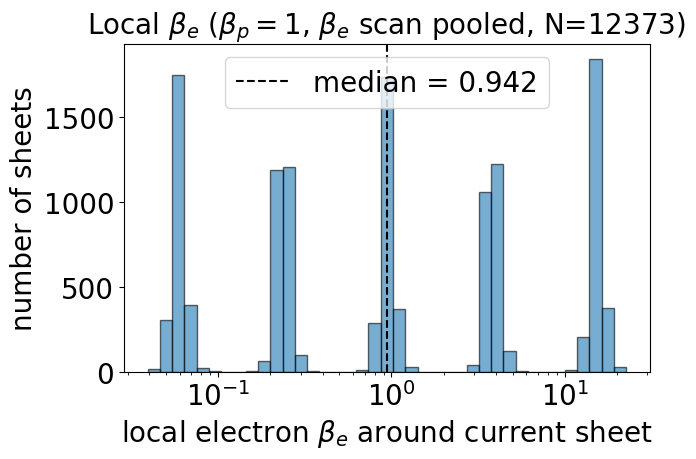

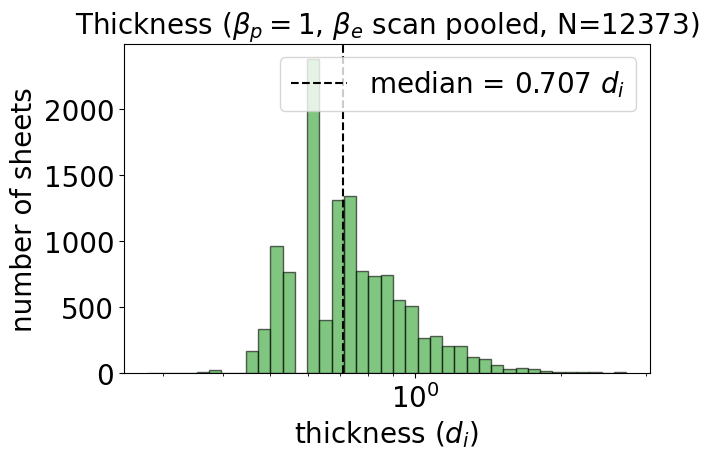

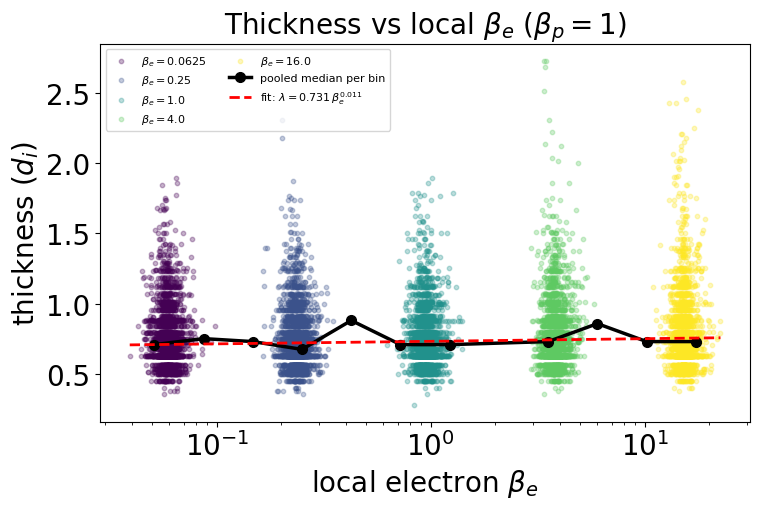

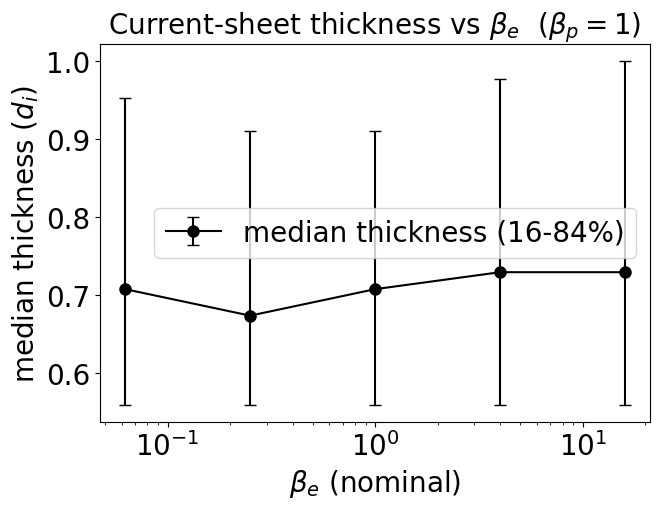


--- pooled sample ---
total sheets              : 12373
local beta_e : median = 0.942  (range 0.0392-22.6)
thickness    : median = 0.707 d_i
power-law fit             : lambda = 0.731 * beta_e_local^0.011
Spearman rho (thick, beta_e_local): 0.033  (p=0.00024)

--- per-run summary (beta_p = 1 fixed) ---
  beta_e       N    med thick   med local be   med local bp
  0.0625    2480        0.707          0.059          0.966
    0.25    2564        0.673          0.236          0.965
     1.0    2434        0.707          0.947          0.970
     4.0    2447        0.729          3.796          0.975
    16.0    2448        0.729         15.284          0.997

Everything saved in:  cs_betae_scan_pooled_bp1_t200-250/


In [7]:
# %% ==========================================================================
#  CELL 2 — PLOTTING  (re-run as often as you like; no recomputation)
# ============================================================================
#  Uses CELL 1's in-memory arrays. If the kernel was restarted, it transparently
#  reloads them from pooled_all.npz instead of recomputing.
# ============================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 20
})

# --- must match CELL 1 (used for titles + to locate the saved data) ---
BETA_P  = 1
TIMES   = list(range(200, 251, 5))
out_dir = str(RESULTS / f"cs_betae_scan_pooled_bp{BETA_P}_t{TIMES[0]}-{TIMES[-1]}")

# --- plotting parameters (tweak these, then re-run THIS cell only) ---
N_BINS_MED  = 12
MIN_PER_BIN = 10

# --- get the pooled data: prefer CELL 1's arrays, else reload from disk ---
try:
    thickness
except NameError:
    print("pooled arrays not in memory -> loading from disk ...", flush=True)
    d = np.load(f"{out_dir}/pooled_all.npz")
    run_beta_e   = d["beta_e"];       snap_time    = d["time"]
    thickness    = d["thickness_di"]; local_beta_p = d["local_beta_p"]
    local_beta_e = d["local_beta_e"]

present = sorted(np.unique(run_beta_e).tolist())   # electron-beta runs actually present


# ============================================================
# Pooled distributions (local electron beta + thickness)
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta_e,
         bins=np.logspace(np.log10(local_beta_e.min()), np.log10(local_beta_e.max()), 40),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta_e), color="black", linestyle="--",
            label=f"median = {np.median(local_beta_e):.3f}")
plt.xscale("log")
plt.xlabel(r"local electron $\beta_e$ around current sheet"); plt.ylabel("number of sheets")
plt.title(rf"Local $\beta_e$ ($\beta_p={BETA_P}$, $\beta_e$ scan pooled, N={len(local_beta_e)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_betae_pooled.png", dpi=300); plt.show()

plt.figure(figsize=(7, 5))
plt.hist(thickness,
         bins=np.logspace(np.log10(thickness.min()), np.log10(thickness.max()), 40),
         alpha=0.6, edgecolor="black", color="tab:green")
plt.axvline(np.median(thickness), color="black", linestyle="--",
            label=f"median = {np.median(thickness):.3f} $d_i$")
plt.xscale("log")
plt.xlabel(r"thickness $(d_i)$"); plt.ylabel("number of sheets")
plt.title(rf"Thickness ($\beta_p={BETA_P}$, $\beta_e$ scan pooled, N={len(thickness)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_thickness_pooled.png", dpi=300); plt.show()


# ============================================================
# Thickness vs local ELECTRON beta (pooled) + power-law fit
# ============================================================
edges = np.logspace(np.log10(local_beta_e.min()), np.log10(local_beta_e.max()), N_BINS_MED + 1)
cen, med, cnt = [], [], []
summary_rows = []
for i in range(N_BINS_MED):
    lo, hi = edges[i], edges[i + 1]
    sel = (local_beta_e >= lo) & (local_beta_e < hi)
    if sel.sum() == 0:
        continue
    cen.append(np.sqrt(lo * hi)); med.append(np.median(thickness[sel])); cnt.append(int(sel.sum()))
    summary_rows.append([lo, hi, int(sel.sum()),
                         np.median(thickness[sel]), np.mean(thickness[sel])])
cen, med, cnt = np.array(cen), np.array(med), np.array(cnt)

with open(f"{out_dir}/binned_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["local_betae_lo", "local_betae_hi", "n_sheets",
                "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

fit_ok = cnt >= MIN_PER_BIN
a = b = np.nan
if fit_ok.sum() >= 2:
    b, logA = np.polyfit(np.log10(cen[fit_ok]), np.log10(med[fit_ok]), 1)
    a = 10 ** logA

rho, pval = spearmanr(local_beta_e, thickness)

colors = {be: plt.cm.viridis(i / max(1, len(present) - 1)) for i, be in enumerate(present)}

plt.figure(figsize=(8, 5.5))
for be in present:
    m = run_beta_e == be
    plt.scatter(local_beta_e[m], thickness[m], s=10, alpha=0.30,
                color=colors[be], label=fr"$\beta_e={be}$")
plt.plot(cen, med, "o-", color="black", lw=2.5, ms=7, label="pooled median per bin")
if np.isfinite(b):
    xx = np.logspace(np.log10(local_beta_e.min()), np.log10(local_beta_e.max()), 60)
    plt.plot(xx, a * xx**b, "--", color="red", lw=2,
             label=fr"fit: $\lambda = {a:.3f}\,\beta_e^{{{b:.3f}}}$")
plt.xscale("log")
plt.xlabel(r"local electron $\beta_e$"); plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta_e$ ($\beta_p={BETA_P}$)")
plt.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_local_betae_pooled.png", dpi=300); plt.show()


# ============================================================
# Thickness vs nominal beta_e (per-run medians)
# ============================================================
be_arr  = np.array(present, float)
med_th  = np.array([np.median(thickness[run_beta_e == be]) for be in present])
th_lo   = np.array([np.percentile(thickness[run_beta_e == be], 16) for be in present])
th_hi   = np.array([np.percentile(thickness[run_beta_e == be], 84) for be in present])
med_lbe = np.array([np.median(local_beta_e[run_beta_e == be]) for be in present])
med_lbp = np.array([np.median(local_beta_p[run_beta_e == be]) for be in present])

plt.figure(figsize=(7, 5.5))
plt.errorbar(be_arr, med_th, yerr=[med_th - th_lo, th_hi - med_th],
             fmt="o-", ms=8, capsize=4, color="k", label="median thickness (16-84%)")
plt.xscale("log")
plt.xlabel(r"$\beta_e$ (nominal)"); plt.ylabel(r"median thickness $(d_i)$")
plt.title(rf"Current-sheet thickness vs $\beta_e$  ($\beta_p={BETA_P}$)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_betae.png", dpi=300); plt.show()

with open(f"{out_dir}/per_betae_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_e", "n_sheets", "median_thickness_di", "thick_16", "thick_84",
                "median_local_beta_e", "median_local_beta_p"])
    for i, be in enumerate(present):
        w.writerow([be, int(np.sum(run_beta_e == be)), med_th[i], th_lo[i], th_hi[i],
                    med_lbe[i], med_lbp[i]])


# ============================================================
# Summary
# ============================================================
print("\n--- pooled sample ---")
print(f"total sheets              : {len(thickness)}")
print(f"local beta_e : median = {np.median(local_beta_e):.3f}  (range {local_beta_e.min():.3g}-{local_beta_e.max():.3g})")
print(f"thickness    : median = {np.median(thickness):.3f} d_i")
if np.isfinite(b):
    print(f"power-law fit             : lambda = {a:.3f} * beta_e_local^{b:.3f}")
print(f"Spearman rho (thick, beta_e_local): {rho:.3f}  (p={pval:.2g})")

print("\n--- per-run summary (beta_p = 1 fixed) ---")
print(f"{'beta_e':>8} {'N':>7} {'med thick':>12} {'med local be':>14} {'med local bp':>14}")
for i, be in enumerate(present):
    print(f"{be:>8} {int(np.sum(run_beta_e == be)):>7} {med_th[i]:>12.3f} "
          f"{med_lbe[i]:>14.3f} {med_lbp[i]:>14.3f}")
print(f"\nEverything saved in:  {out_dir}/")